# Final Comparison: BSM vs Monte Carlo vs FFT vs FNN vs GPR

This notebook brings every pricing method in the project together and
evaluates them on **exactly the same option parameters**:

| # | Method | Type |
|---|--------|------|
| 1 | Black-Scholes-Merton (BSM) closed form | analytical ground truth |
| 2 | Monte Carlo (MC), 100,000 paths | simulation |
| 3 | Carr-Madan FFT | characteristic-function / numerical integration |
| 4 | Feedforward neural network (FNN) | ML surrogate, trained in `02_fft_dataset_ml.ipynb` on 35,000 FFT prices |
| 5 | Gaussian Process Regression (GPR) | ML surrogate, trained **here on BSM prices** |

Sections:

1. One shared test set (a strike sweep + a random batch of 1,000 options).
2. Load the trained FNN; train the GPR on BSM-labelled data.
3. Price the shared set with all 5 methods -> overlay graphs + error table vs BSM.
4. Computational efficiency: per-option cost (log-scale bar chart), upfront
   training cost and break-even analysis.
5. **GPR vs FNN head-to-head**: both trained on the *same* BSM-labelled
   data at the *same* sizes (2k / 5k / 10k) - accuracy, training cost,
   inference cost, memory, and GPR's built-in uncertainty estimate.

In [1]:
from __future__ import annotations

import math
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 20261116
np.random.seed(SEED)
torch.manual_seed(SEED)

FFT_N = 16384
FFT_ETA = 0.25
FFT_ALPHA = 1.5
MC_PATHS = 100_000

DATA_DIR = Path("data")
MODELS_DIR = Path("models")
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

FEATURE_NAMES = ["spot", "strike", "rate", "sigma", "tau"]
METHODS = ["BSM", "MC", "FFT", "FNN", "GPR"]
COLORS = {"BSM": "black", "MC": "tab:orange", "FFT": "tab:green", "FNN": "tab:blue", "GPR": "tab:purple"}

device = torch.device("cpu")  # CPU for a like-for-like timing comparison with the numpy pricers


## Pricing functions (copied unchanged from `code.py` / notebooks 01-02)

In [2]:
def norm_cdf(x: float) -> float:
    return 0.5 * math.erfc(-x / math.sqrt(2.0))


def bsm_call(spot: float, strike: float, rate: float, sigma: float, tau: float) -> float:
    """European call price, continuously compounded rate, time-to-maturity tau."""
    if spot <= 0 or strike <= 0 or sigma < 0 or tau < 0:
        raise ValueError("spot and strike must be positive; sigma and tau nonnegative")
    if tau == 0:
        return max(spot - strike, 0.0)
    if sigma == 0:
        return max(spot - strike * math.exp(-rate * tau), 0.0)
    vol_time = sigma * math.sqrt(tau)
    d1 = (math.log(spot / strike) + (rate + 0.5 * sigma * sigma) * tau) / vol_time
    d2 = d1 - vol_time
    return spot * norm_cdf(d1) - strike * math.exp(-rate * tau) * norm_cdf(d2)


def mc_call(spot: float, strike: float, rate: float, sigma: float, tau: float,
            normals: np.ndarray) -> float:
    """One-step exact GBM Monte Carlo estimator using caller-supplied N(0,1) draws."""
    if tau == 0:
        return max(spot - strike, 0.0)
    if sigma == 0:
        return max(spot - strike * math.exp(-rate * tau), 0.0)
    terminal = spot * np.exp((rate - 0.5 * sigma * sigma) * tau
                             + sigma * math.sqrt(tau) * normals)
    return math.exp(-rate * tau) * float(np.maximum(terminal - strike, 0.0).mean())


def carr_madan_call(spot: float, strike: float, rate: float, sigma: float,
                    tau: float, n: int = FFT_N, eta: float = FFT_ETA,
                    alpha: float = FFT_ALPHA) -> float:
    """Carr-Madan FFT inversion for a Black-Scholes European call."""
    if spot <= 0 or strike <= 0 or sigma < 0 or tau < 0:
        raise ValueError("spot and strike must be positive; sigma and tau nonnegative")
    if tau == 0 or sigma == 0:
        return bsm_call(spot, strike, rate, sigma, tau)
    if n < 16 or n & (n - 1):
        raise ValueError("FFT size n must be a power of two >= 16")
    if eta <= 0 or alpha <= 0:
        raise ValueError("eta and alpha must be positive")

    j = np.arange(n)
    u = eta * j
    log_forward = math.log(spot) + (rate - 0.5 * sigma * sigma) * tau
    z = u - 1j * (alpha + 1.0)
    phi = np.exp(1j * z * log_forward - 0.5 * sigma * sigma * tau * z * z)
    denominator = alpha * alpha + alpha - u * u + 1j * (2.0 * alpha + 1.0) * u
    psi = math.exp(-rate * tau) * phi / denominator

    weights = np.ones(n)
    weights[1::2] = 4.0
    weights[2:-1:2] = 2.0
    weights /= 3.0
    weights[0] = 1.0 / 3.0
    weights[-1] = 1.0 / 3.0
    b = math.pi / eta
    integrand = np.exp(1j * b * u) * psi * eta * weights
    fft_values = np.fft.fft(integrand)
    dk = 2.0 * math.pi / (n * eta)
    log_strike_grid = -b + dk * np.arange(n)
    calls = np.exp(-alpha * log_strike_grid) * fft_values.real / math.pi
    target = math.log(strike)
    if target < log_strike_grid[0] or target > log_strike_grid[-1]:
        uu = u
        direct_integrand = np.exp(-1j * uu * target) * psi
        direct_integrand[0] *= 0.5
        price = math.exp(-alpha * target) * eta * float(direct_integrand.real.sum()) / math.pi
    else:
        price = float(np.interp(target, log_strike_grid, calls))
    return max(price, 0.0)


def make_dataset(count: int, seed: int) -> list[dict[str, float]]:
    """Generate valid parameter sets; rates may be negative, all other inputs positive."""
    rng = np.random.default_rng(seed)
    spots = rng.uniform(50.0, 200.0, count)
    moneyness = rng.uniform(0.70, 1.30, count)
    rates = rng.uniform(-0.02, 0.10, count)
    sigmas = rng.uniform(0.05, 0.80, count)
    taus = rng.uniform(0.05, 3.0, count)
    return [dict(spot=float(s), strike=float(s * m), rate=float(r),
                 sigma=float(v), tau=float(t))
            for s, m, r, v, t in zip(spots, moneyness, rates, sigmas, taus)]


def error_summary(true: np.ndarray, pred: np.ndarray, floor: float = 0.01) -> dict[str, float]:
    """Errors vs ground truth. Relative error denominator floored at $0.01 (see notebook 02)."""
    abs_err = np.abs(pred - true)
    return {
        "mean_abs_error": float(abs_err.mean()),
        "max_abs_error": float(abs_err.max()),
        "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        "mean_rel_error": float((abs_err / np.maximum(true, floor)).mean()),
        "r2": float(r2_score(true, pred)),
    }


## 1. One shared test set

Every method below is evaluated on these **same** rows - nothing is reused
from notebooks 01/02's own test sets.

- **Strike sweep**: spot=100, r=5%, sigma=25%, tau=1y, 61 strikes from 70 to 130
  - a smooth 1-D curve where all methods can be overlaid visually.
- **Random batch**: 1,000 options sampled over the full training ranges with a
  seed never used before (`SEED + 2026`), so they are unseen by both ML models.

In [3]:
SWEEP_BASE = dict(spot=100.0, rate=0.05, sigma=0.25, tau=1.0)
sweep_strikes = np.linspace(70.0, 130.0, 61)
sweep_options = [dict(SWEEP_BASE, strike=float(k)) for k in sweep_strikes]

N_SHARED = 1000
random_options = make_dataset(N_SHARED, SEED + 2026)

sweep_df = pd.DataFrame(sweep_options)[FEATURE_NAMES]
random_df = pd.DataFrame(random_options)[FEATURE_NAMES]
print(f"Strike sweep: {len(sweep_df)} options   Random batch: {len(random_df)} options")
random_df.describe()


Strike sweep: 61 options   Random batch: 1000 options


,spot,strike,rate,sigma,tau
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,126.732481,126.980097,0.037925,0.419448,1.536370
std,43.691677,49.641291,0.034389,0.211165,0.840345
min,50.304399,37.853283,-0.019960,0.050689,0.051362
25%,90.432687,86.501844,0.008472,0.238020,0.811975
50%,127.756953,124.309497,0.035981,0.417969,1.552315
75%,165.994216,162.641589,0.067744,0.595514,2.253684
max,199.837558,252.783268,0.099981,0.799842,2.997119


## 2. ML models

### 2a. Load the FNN trained in notebook 02

Same architecture (5 -> 128 -> 128 -> 64 -> 32 -> 1, ReLU), weights and
input/output scalers loaded from `models/`. No retraining.

In [4]:
class OptionPricerMLP(nn.Module):
    def __init__(self, n_features: int = 5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


fnn = OptionPricerMLP(len(FEATURE_NAMES)).to(device)
fnn.load_state_dict(torch.load(MODELS_DIR / "option_pricer_mlp.pt", map_location=device, weights_only=True))
fnn.eval()
fnn_scaler_X = joblib.load(MODELS_DIR / "scaler_X.joblib")
fnn_scaler_y = joblib.load(MODELS_DIR / "scaler_y.joblib")


def predict_mlp(model: nn.Module, scaler_X: StandardScaler, scaler_y: StandardScaler,
                X: np.ndarray) -> np.ndarray:
    """Single batched forward pass on raw (unscaled) parameters -> prices."""
    with torch.no_grad():
        xt = torch.from_numpy(scaler_X.transform(X).astype(np.float32)).to(device)
        out = model(xt).cpu().numpy()
    return scaler_y.inverse_transform(out).flatten()


n_params = sum(p.numel() for p in fnn.parameters())
print(f"Loaded FNN with {n_params:,} parameters")


Loaded FNN with 27,649 parameters


### 2b. Train GPR on BSM prices

Notebook 02 already trained GPR on **FFT** labels to mirror the paper. Here
we implement GPR as a direct surrogate for the **Black-Scholes formula**:
the inputs are the training-split parameter rows of notebook 02's dataset
(same `train_test_split` seed, so none of notebook 02's test rows are used),
and the labels are the **exact BSM closed-form prices**.

Same recipe as notebook 02 so results are comparable:

- Kernel `C * RBF(5 anisotropic length scales) + White noise`.
- Hyperparameters fitted once by marginal-likelihood optimization on the
  smallest size (2,000 points), then reused fixed at 5,000 and 10,000 -
  exact GPR is `O(n^3)` so refitting hyperparameters at each size is
  prohibitively slow.
- The 10,000-point GPR is the one used in the 5-way comparison.

In [5]:
dataset_df = pd.read_csv(DATA_DIR / "fft_training_dataset.csv")
X_all = dataset_df[FEATURE_NAMES].to_numpy(dtype=np.float64)
y_all_fft = dataset_df["fft_price"].to_numpy(dtype=np.float64)

# Reproduce notebook 02's split exactly (same arrays, same random_state) and keep only the train part.
X_train_full, _, y_train_fft, _ = train_test_split(X_all, y_all_fft, test_size=0.30, random_state=SEED)

# BSM labels for the training inputs.
y_train_bsm = np.array([bsm_call(*row) for row in X_train_full])
print(f"Training pool: {len(X_train_full):,} rows; max |BSM - FFT| label difference = "
      f"{np.abs(y_train_bsm - y_train_fft).max():.2e}")

ML_TRAIN_SIZES = [2000, 5000, 10000]


Training pool: 35,000 rows; max |BSM - FFT| label difference = 5.80e-04


In [6]:
def fit_gpr(X: np.ndarray, y: np.ndarray, kernel, optimize: bool) -> dict:
    sx = StandardScaler().fit(X)
    sy = StandardScaler().fit(y.reshape(-1, 1))
    gpr = GaussianProcessRegressor(kernel=kernel, optimizer="fmin_l_bfgs_b" if optimize else None,
                                   n_restarts_optimizer=1 if optimize else 0, random_state=SEED)
    t0 = time.perf_counter()
    gpr.fit(sx.transform(X), sy.transform(y.reshape(-1, 1)).flatten())
    return {"model": gpr, "sx": sx, "sy": sy, "fit_seconds": time.perf_counter() - t0}


def predict_gpr(g: dict, X: np.ndarray, return_std: bool = False):
    Xs = g["sx"].transform(X)
    if return_std:
        mu, sd = g["model"].predict(Xs, return_std=True)
        scale = g["sy"].scale_[0]
        return g["sy"].inverse_transform(mu.reshape(-1, 1)).flatten(), sd * scale
    mu = g["model"].predict(Xs)
    return g["sy"].inverse_transform(mu.reshape(-1, 1)).flatten()


init_kernel = (ConstantKernel(1.0, (1e-2, 1e2))
               * RBF(length_scale=np.ones(len(FEATURE_NAMES)), length_scale_bounds=(1e-2, 1e2))
               + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e-1)))

base_n = ML_TRAIN_SIZES[0]
print(f"Optimizing GPR kernel hyperparameters on {base_n:,} BSM-labelled points...")
gpr_base = fit_gpr(X_train_full[:base_n], y_train_bsm[:base_n], init_kernel, optimize=True)
fixed_kernel = gpr_base["model"].kernel_
print(f"  done in {gpr_base['fit_seconds']:.1f}s; learned kernel: {fixed_kernel}")

gpr_models = {}
for n in ML_TRAIN_SIZES:
    gpr_models[n] = fit_gpr(X_train_full[:n], y_train_bsm[:n], fixed_kernel, optimize=False)
    print(f"GPR n={n:6,d}: exact fit (Cholesky) took {gpr_models[n]['fit_seconds']:.2f}s")

gpr = gpr_models[max(ML_TRAIN_SIZES)]


Optimizing GPR kernel hyperparameters on 2,000 BSM-labelled points...


  done in 25.7s; learned kernel: 2.59**2 * RBF(length_scale=[1.21, 1.15, 8.14, 1.87, 1.85]) + WhiteKernel(noise_level=1.9e-05)
GPR n= 2,000: exact fit (Cholesky) took 0.10s


GPR n= 5,000: exact fit (Cholesky) took 1.21s


GPR n=10,000: exact fit (Cholesky) took 7.89s


## 3. Price the shared test set with all 5 methods

Every method gets identical inputs. MC uses 100,000 paths per option with
fresh normal draws from one seeded generator. Each method is also timed
here (looped one option at a time for BSM / MC / FFT; one batched call for
FNN / GPR, which is how surrogate models are used in practice).

In [7]:
def price_all_methods(options: list[dict], mc_seed: int) -> tuple[pd.DataFrame, dict]:
    X = pd.DataFrame(options)[FEATURE_NAMES].to_numpy(dtype=np.float64)
    out = pd.DataFrame(options)[FEATURE_NAMES].copy()
    seconds = {}

    t0 = time.perf_counter(); out["BSM"] = [bsm_call(**p) for p in options]; seconds["BSM"] = time.perf_counter() - t0

    rng = np.random.default_rng(mc_seed)
    t0 = time.perf_counter()
    out["MC"] = [mc_call(**p, normals=rng.standard_normal(MC_PATHS)) for p in options]
    seconds["MC"] = time.perf_counter() - t0

    t0 = time.perf_counter(); out["FFT"] = [carr_madan_call(**p) for p in options]; seconds["FFT"] = time.perf_counter() - t0
    t0 = time.perf_counter(); out["FNN"] = predict_mlp(fnn, fnn_scaler_X, fnn_scaler_y, X); seconds["FNN"] = time.perf_counter() - t0
    t0 = time.perf_counter(); out["GPR"] = predict_gpr(gpr, X); seconds["GPR"] = time.perf_counter() - t0
    return out, seconds


sweep_prices, _ = price_all_methods(sweep_options, mc_seed=SEED + 1)
random_prices, random_seconds = price_all_methods(random_options, mc_seed=SEED + 2)

sweep_prices.to_csv(DATA_DIR / "comparison_sweep_prices.csv", index=False)
random_prices.to_csv(DATA_DIR / "comparison_shared_prices.csv", index=False)
sweep_prices.head()


,spot,strike,rate,sigma,tau,BSM,MC,FFT,FNN,GPR
0,100.0,70.0,0.05,0.25,1.0,33.856456,33.918575,33.856448,33.963470,33.653256
1,100.0,71.0,0.05,0.25,1.0,32.972161,33.076730,32.972157,33.095005,32.832851
2,100.0,72.0,0.05,0.25,1.0,32.095394,32.204437,32.095393,32.227268,32.009101
3,100.0,73.0,0.05,0.25,1.0,31.226661,31.117228,31.226660,31.362078,31.183592
4,100.0,74.0,0.05,0.25,1.0,30.366471,30.299093,30.366468,30.487984,30.357851


### 3a. All 5 methods on the strike sweep (same x-axis)

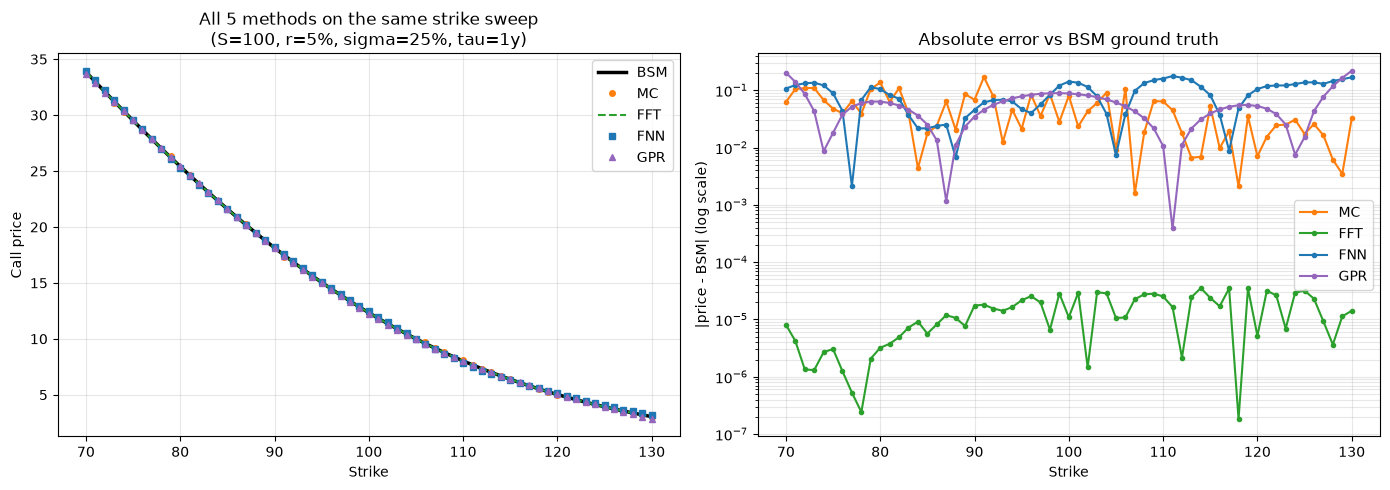

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

styles = {"BSM": dict(lw=2.5), "MC": dict(ls="none", marker="o", ms=4),
          "FFT": dict(ls="--", lw=1.5), "FNN": dict(ls="none", marker="s", ms=4),
          "GPR": dict(ls="none", marker="^", ms=4)}
for m in METHODS:
    ax1.plot(sweep_strikes, sweep_prices[m], color=COLORS[m], label=m, **styles[m])
ax1.set_xlabel("Strike")
ax1.set_ylabel("Call price")
ax1.set_title("All 5 methods on the same strike sweep\n(S=100, r=5%, sigma=25%, tau=1y)")
ax1.legend()
ax1.grid(True, alpha=0.3)

for m in METHODS[1:]:
    ax2.semilogy(sweep_strikes, np.abs(sweep_prices[m] - sweep_prices["BSM"]) + 1e-12,
                 color=COLORS[m], label=m, marker="o", ms=3)
ax2.set_xlabel("Strike")
ax2.set_ylabel("|price - BSM| (log scale)")
ax2.set_title("Absolute error vs BSM ground truth")
ax2.legend()
ax2.grid(True, which="both", alpha=0.3)

fig.tight_layout()
fig.savefig(DATA_DIR / "comparison_strike_sweep.png", dpi=150)
plt.show()


### 3b. All 5 methods on the 1,000-option random batch (sorted by BSM price)

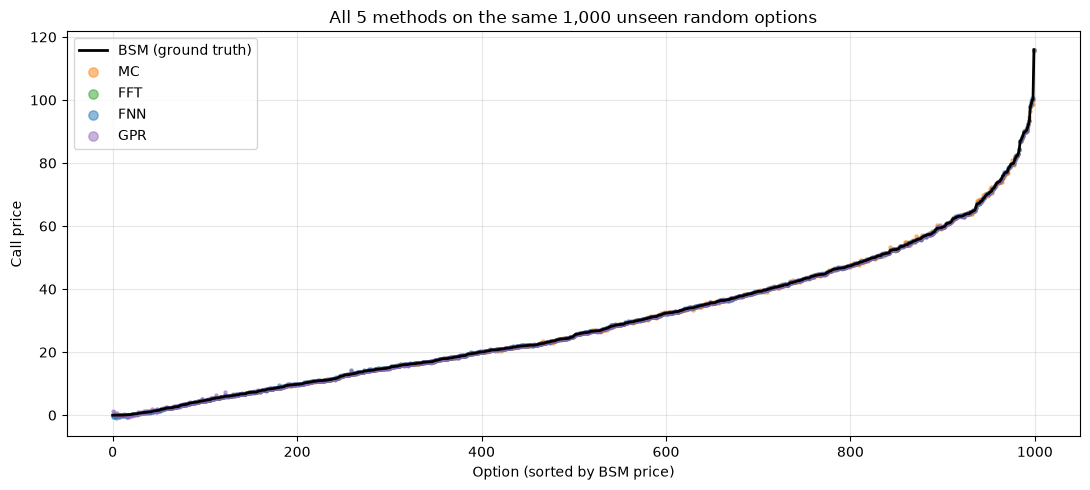

In [9]:
order = np.argsort(random_prices["BSM"].to_numpy())
idx = np.arange(N_SHARED)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(idx, random_prices["BSM"].to_numpy()[order], color=COLORS["BSM"], lw=2, label="BSM (ground truth)")
for m in ["MC", "FFT", "FNN", "GPR"]:
    ax.scatter(idx, random_prices[m].to_numpy()[order], s=5, alpha=0.5, color=COLORS[m], label=m)
ax.set_xlabel("Option (sorted by BSM price)")
ax.set_ylabel("Call price")
ax.set_title("All 5 methods on the same 1,000 unseen random options")
ax.legend(markerscale=3)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(DATA_DIR / "comparison_random_batch.png", dpi=150)
plt.show()


### 3c. Summary error table vs BSM ground truth (random batch)

Relative error uses a $0.01 floor on the denominator (same convention as
notebook 02) so near-worthless deep-OTM options don't dominate.

In [10]:
true = random_prices["BSM"].to_numpy()
error_df = pd.DataFrame({m: error_summary(true, random_prices[m].to_numpy()) for m in ["MC", "FFT", "FNN", "GPR"]}).T
error_df.index.name = "method"
error_df.to_csv(DATA_DIR / "comparison_error_summary.csv")
error_df.style.format({"mean_abs_error": "{:.2e}", "max_abs_error": "{:.2e}", "rmse": "{:.2e}",
                       "mean_rel_error": "{:.3%}", "r2": "{:.6f}"})


,mean_abs_error,max_abs_error,rmse,mean_rel_error,r2
method,,,,,
MC,1.45e-01,1.44e+00,2.49e-01,0.535%,0.999865
FFT,1.30e-05,2.72e-04,2.72e-05,0.001%,1.000000
FNN,1.28e-01,1.18e+00,1.72e-01,48.027%,0.999936
GPR,7.13e-02,1.22e+00,1.41e-01,42.811%,0.999957


## 4. Computational efficiency

### 4a. Per-option cost on the 1,000-option batch

BSM / MC / FFT are evaluated option-by-option (that's how they're used when
each new parameter set arrives); FNN and GPR price the whole batch in one
call. A second timing pass is run so the numbers aren't dominated by
first-call warm-up.

In [11]:
def time_per_option(fn, repeats: int = 3) -> float:
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best / N_SHARED * 1e6  # microseconds per option


X_rand = random_df.to_numpy(dtype=np.float64)
rng_t = np.random.default_rng(SEED + 3)
timing_us = {
    "BSM": time_per_option(lambda: [bsm_call(**p) for p in random_options]),
    "MC": time_per_option(lambda: [mc_call(**p, normals=rng_t.standard_normal(MC_PATHS)) for p in random_options], repeats=1),
    "FFT": time_per_option(lambda: [carr_madan_call(**p) for p in random_options]),
    "FNN": time_per_option(lambda: predict_mlp(fnn, fnn_scaler_X, fnn_scaler_y, X_rand)),
    "GPR": time_per_option(lambda: predict_gpr(gpr, X_rand)),
}
timing_df = pd.DataFrame({"us_per_option": timing_us})
timing_df["speed_up_vs_fft"] = timing_df.loc["FFT", "us_per_option"] / timing_df["us_per_option"]
timing_df["speed_up_vs_mc"] = timing_df.loc["MC", "us_per_option"] / timing_df["us_per_option"]
timing_df.index.name = "method"
timing_df.to_csv(DATA_DIR / "comparison_timing.csv")
timing_df


,us_per_option,speed_up_vs_fft,speed_up_vs_mc
method,,,
BSM,0.535750,1498.370028,2318.428117
MC,1242.097875,0.646287,1.000000
FFT,802.751750,1.000000,1.547300
FNN,0.483666,1659.723339,2568.090113
GPR,77.864542,10.309593,15.952035


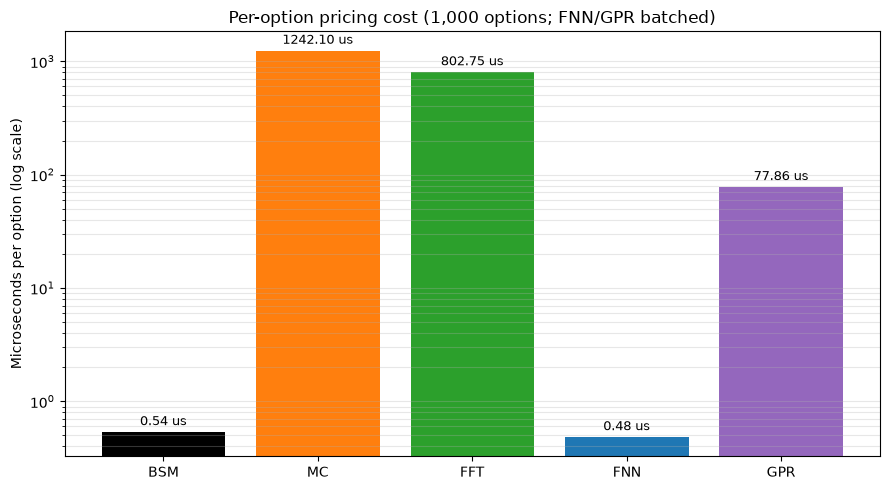

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(timing_df.index, timing_df["us_per_option"], color=[COLORS[m] for m in timing_df.index])
ax.set_yscale("log")
ax.set_ylabel("Microseconds per option (log scale)")
ax.set_title("Per-option pricing cost (1,000 options; FNN/GPR batched)")
for b, v in zip(bars, timing_df["us_per_option"]):
    ax.text(b.get_x() + b.get_width() / 2, v * 1.15, f"{v:.2f} us", ha="center", fontsize=9)
ax.grid(True, axis="y", which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(DATA_DIR / "comparison_timing.png", dpi=150)
plt.show()


### 4b. Upfront cost and break-even

The ML surrogates are only cheap *after* paying a one-time cost: generating
the labelled dataset (FFT pricing every training row) and fitting the
model. The break-even number of queries is

`upfront_seconds / (FFT_us_per_option - ML_us_per_option)`

i.e. how many new options must be priced before the surrogate has saved
more time than it cost to build. This needs measured training times for
both models, so it is computed in Section 5b after the GPR and FNN are
trained on identical data.

**Why BSM is still the fastest here.** BSM is a closed-form formula, so it is
effectively free. The real efficiency story is for models *without* a
closed form (Heston, VG, ...): there FFT or MC is the only exact-ish pricer,
and an FNN/GPR trained once on FFT prices replaces every subsequent
FFT/MC call at a tiny fraction of the cost. Black-Scholes is used here as a
validated proof-of-concept because the ground truth is known exactly.

## 5. GPR vs FNN head-to-head

To compare the two ML approaches fairly, both are trained on **identical
data**: the first 2,000 / 5,000 / 10,000 BSM-labelled training rows from
Section 2b. The FNN uses the same architecture as notebook 02, trained with
Adam + cosine learning-rate decay for a fixed budget of ~14,000 gradient
steps (about the same number of steps notebook 02's model got), so smaller
datasets aren't under-trained. All models are evaluated on the shared
1,000-option random batch.

In [13]:
def train_fnn(X: np.ndarray, y: np.ndarray, total_steps: int = 14_000, batch_size: int = 256,
              lr: float = 1e-3, seed: int = SEED) -> dict:
    torch.manual_seed(seed)
    sx = StandardScaler().fit(X)
    sy = StandardScaler().fit(y.reshape(-1, 1))
    Xt = torch.from_numpy(sx.transform(X).astype(np.float32))
    yt = torch.from_numpy(sy.transform(y.reshape(-1, 1)).astype(np.float32))
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xt, yt),
                                         batch_size=batch_size, shuffle=True)
    model = OptionPricerMLP(len(FEATURE_NAMES))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps)
    loss_fn = nn.MSELoss()
    steps = 0
    t0 = time.perf_counter()
    model.train()
    while steps < total_steps:
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step(); sched.step()
            steps += 1
            if steps >= total_steps:
                break
    model.eval()
    return {"model": model, "sx": sx, "sy": sy, "fit_seconds": time.perf_counter() - t0}


fnn_models = {}
for n in ML_TRAIN_SIZES:
    fnn_models[n] = train_fnn(X_train_full[:n], y_train_bsm[:n])
    print(f"FNN n={n:6,d}: trained in {fnn_models[n]['fit_seconds']:.1f}s")


FNN n= 2,000: trained in 18.1s


FNN n= 5,000: trained in 18.2s


FNN n=10,000: trained in 18.2s


In [14]:
fnn_bytes = n_params * 4  # float32 weights
rows = []
for n in ML_TRAIN_SIZES:
    g, f = gpr_models[n], fnn_models[n]

    t0 = time.perf_counter(); g_pred = predict_gpr(g, X_rand); g_t = time.perf_counter() - t0
    t0 = time.perf_counter(); f_pred = predict_mlp(f["model"], f["sx"], f["sy"], X_rand); f_t = time.perf_counter() - t0

    for name, pred, fit_s, pred_s, mem in [
        ("GPR", g_pred, g["fit_seconds"], g_t, n * n * 8 + n * 6 * 8),  # Cholesky factor + training data/alpha
        ("FNN", f_pred, f["fit_seconds"], f_t, fnn_bytes),
    ]:
        rows.append({"model": name, "train_size": n, "label_source": "BSM",
                     **error_summary(true, pred),
                     "fit_seconds": fit_s, "predict_us_per_option": pred_s / N_SHARED * 1e6,
                     "model_memory_MB": mem / 1e6})

# Production FNN from notebook 02 (35k FFT labels, original recipe) for reference.
t0 = time.perf_counter(); p = predict_mlp(fnn, fnn_scaler_X, fnn_scaler_y, X_rand); t = time.perf_counter() - t0
rows.append({"model": "FNN (nb 02)", "train_size": 35000, "label_source": "FFT",
             **error_summary(true, p), "fit_seconds": float("nan"),
             "predict_us_per_option": t / N_SHARED * 1e6, "model_memory_MB": fnn_bytes / 1e6})

gpr_vs_fnn = pd.DataFrame(rows)
gpr_vs_fnn.to_csv(DATA_DIR / "gpr_vs_fnn_bsm.csv", index=False)
gpr_vs_fnn.style.format({"mean_abs_error": "{:.4f}", "max_abs_error": "{:.4f}", "rmse": "{:.4f}",
                         "mean_rel_error": "{:.2%}", "r2": "{:.6f}", "fit_seconds": "{:.2f}",
                         "predict_us_per_option": "{:.2f}", "model_memory_MB": "{:.2f}"})


,model,train_size,label_source,mean_abs_error,max_abs_error,rmse,mean_rel_error,r2,fit_seconds,predict_us_per_option,model_memory_MB
0,GPR,2000,BSM,0.1425,3.5441,0.3129,101.12%,0.999787,0.10,17.02,32.10
1,FNN,2000,BSM,0.2840,3.2415,0.4012,54.57%,0.999650,18.15,0.96,0.11
2,GPR,5000,BSM,0.0931,2.5657,0.2023,63.19%,0.999911,1.21,43.29,200.24
3,FNN,5000,BSM,0.1955,2.1173,0.2689,34.57%,0.999843,18.24,0.66,0.11
4,GPR,10000,BSM,0.0713,1.2155,0.1411,42.81%,0.999957,7.89,77.40,800.48
5,FNN,10000,BSM,0.1615,2.0270,0.2217,40.23%,0.999893,18.17,0.94,0.11
6,FNN (nb 02),35000,FFT,0.1285,1.1797,0.1720,48.03%,0.999936,nan,0.70,0.11


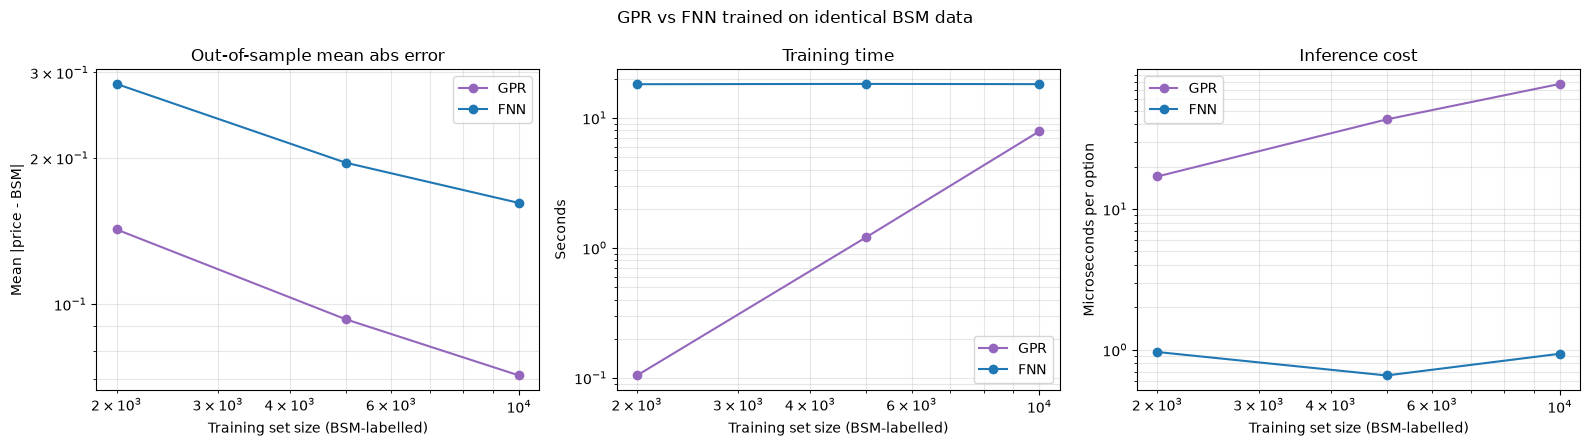

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, c in [("GPR", COLORS["GPR"]), ("FNN", COLORS["FNN"])]:
    d = gpr_vs_fnn[gpr_vs_fnn["model"] == name]
    axes[0].plot(d["train_size"], d["mean_abs_error"], "o-", color=c, label=name)
    axes[1].plot(d["train_size"], d["fit_seconds"], "o-", color=c, label=name)
    axes[2].plot(d["train_size"], d["predict_us_per_option"], "o-", color=c, label=name)

for ax, title, ylabel in zip(
        axes,
        ["Out-of-sample mean abs error", "Training time", "Inference cost"],
        ["Mean |price - BSM|", "Seconds", "Microseconds per option"]):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Training set size (BSM-labelled)")
    ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3); ax.legend()

fig.suptitle("GPR vs FNN trained on identical BSM data")
fig.tight_layout()
fig.savefig(DATA_DIR / "gpr_vs_fnn_scaling.png", dpi=150)
plt.show()


### 5a. Error distribution and GPR's uncertainty estimate (n = 10,000)

A practical advantage of GPR over an FNN is that it returns a **predictive
standard deviation** with every price for free. If that uncertainty is
well-calibrated, about 95% of true prices should fall within +/- 2 sigma of
the GPR mean.

GPR: 92.9% of true BSM prices lie within +/-2 sigma (ideal ~95%)
Correlation between GPR sigma and |error|: 0.480


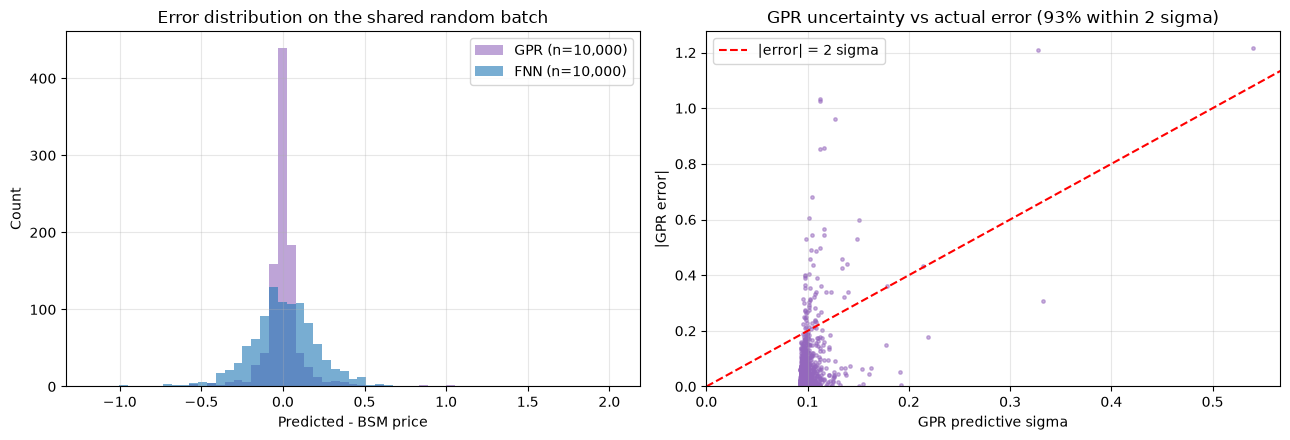

In [16]:
n_max = max(ML_TRAIN_SIZES)
g_mu, g_sd = predict_gpr(gpr_models[n_max], X_rand, return_std=True)
f_pred = predict_mlp(fnn_models[n_max]["model"], fnn_models[n_max]["sx"], fnn_models[n_max]["sy"], X_rand)
g_err = g_mu - true
f_err = f_pred - true

coverage_2sd = float((np.abs(g_err) <= 2 * g_sd).mean())
print(f"GPR: {coverage_2sd:.1%} of true BSM prices lie within +/-2 sigma (ideal ~95%)")
print(f"Correlation between GPR sigma and |error|: {np.corrcoef(g_sd, np.abs(g_err))[0, 1]:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.linspace(min(g_err.min(), f_err.min()), max(g_err.max(), f_err.max()), 60)
ax1.hist(g_err, bins=bins, alpha=0.6, color=COLORS["GPR"], label=f"GPR (n={n_max:,})")
ax1.hist(f_err, bins=bins, alpha=0.6, color=COLORS["FNN"], label=f"FNN (n={n_max:,})")
ax1.set_xlabel("Predicted - BSM price"); ax1.set_ylabel("Count")
ax1.set_title("Error distribution on the shared random batch"); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.scatter(g_sd, np.abs(g_err), s=6, alpha=0.5, color=COLORS["GPR"])
lim = [0, max(g_sd.max() * 2, np.abs(g_err).max()) * 1.05]
ax2.plot(lim, [2 * lim[0], 2 * lim[1]], "r--", label="|error| = 2 sigma")
ax2.set_xlim(0, g_sd.max() * 1.05); ax2.set_ylim(lim)
ax2.set_xlabel("GPR predictive sigma"); ax2.set_ylabel("|GPR error|")
ax2.set_title(f"GPR uncertainty vs actual error ({coverage_2sd:.0%} within 2 sigma)")
ax2.legend(); ax2.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(DATA_DIR / "gpr_vs_fnn_errors.png", dpi=150)
plt.show()


### 5b. Break-even analysis (uses the measured fit times above)

In [17]:
fft_us = timing_df.loc["FFT", "us_per_option"]
fft_label_seconds_per_row = fft_us / 1e6
breakeven_rows = []
for name, models in [("GPR", gpr_models), ("FNN", fnn_models)]:
    n = n_max
    upfront = n * fft_label_seconds_per_row + models[n]["fit_seconds"]  # FFT-label the data + fit
    ml_us = gpr_vs_fnn.query("model == @name and train_size == @n")["predict_us_per_option"].iloc[0]
    breakeven_rows.append({"model": name, "train_size": n, "upfront_seconds": upfront,
                           "ml_us_per_option": ml_us, "fft_us_per_option": fft_us,
                           "break_even_queries": upfront / ((fft_us - ml_us) / 1e6)})
breakeven_df = pd.DataFrame(breakeven_rows)
breakeven_df


,model,train_size,upfront_seconds,ml_us_per_option,fft_us_per_option,break_even_queries
0,GPR,10000,15.919190,77.403125,802.75175,21946.950223
1,FNN,10000,26.196839,0.936541,802.75175,32671.915754


### 5c. Automatic verdict

In [18]:
g10 = gpr_vs_fnn.query("model == 'GPR' and train_size == @n_max").iloc[0]
f10 = gpr_vs_fnn.query("model == 'FNN' and train_size == @n_max").iloc[0]
acc_winner = "GPR" if g10["mean_abs_error"] < f10["mean_abs_error"] else "FNN"
print(f"At n={n_max:,} BSM-labelled points:")
print(f"  accuracy (mean abs err): GPR {g10['mean_abs_error']:.4f} vs FNN {f10['mean_abs_error']:.4f} -> {acc_winner} more accurate")
print(f"  training time          : GPR {g10['fit_seconds']:.2f}s vs FNN {f10['fit_seconds']:.2f}s")
print(f"  inference              : GPR {g10['predict_us_per_option']:.2f} us vs FNN {f10['predict_us_per_option']:.2f} us per option "
      f"(FNN {g10['predict_us_per_option'] / f10['predict_us_per_option']:.0f}x faster)")
print(f"  memory                 : GPR {g10['model_memory_MB']:.1f} MB vs FNN {f10['model_memory_MB']:.2f} MB")
gpr_mono = bool(gpr_vs_fnn.query("model == 'GPR'")["mean_abs_error"].is_monotonic_decreasing)
fnn_mono = bool(gpr_vs_fnn.query("model == 'FNN'")["mean_abs_error"].is_monotonic_decreasing)
print(f"  error falls monotonically with training size: GPR {gpr_mono}, FNN {fnn_mono}")


At n=10,000 BSM-labelled points:
  accuracy (mean abs err): GPR 0.0713 vs FNN 0.1615 -> GPR more accurate
  training time          : GPR 7.89s vs FNN 18.17s
  inference              : GPR 77.40 us vs FNN 0.94 us per option (FNN 83x faster)
  memory                 : GPR 800.5 MB vs FNN 0.11 MB
  error falls monotonically with training size: GPR True, FNN True


## Conclusions

- **Agreement.** On identical inputs, MC and FFT agree with BSM to
  Monte-Carlo noise (~1e-2) and FFT discretization error (~1e-5)
  respectively; both ML surrogates track the BSM curve closely, with errors
  of a few cents to ~10 cents (see the error table in 3c).
- **Efficiency.** Per query, the ML surrogates are orders of magnitude
  cheaper than FFT and MC (bar chart in 4a). BSM is cheaper still only
  because it is closed form - for models without one (Heston, VG), FFT/MC
  are the baseline and a trained surrogate replaces them after a one-time
  upfront cost (break-even in 5b).
- **GPR vs FNN.**
  - *Accuracy at small/medium data*: GPR is a very data-efficient
    interpolator - at the same training size it is typically more accurate
    than the FNN (see 5 / 5c).
  - *Scalability*: GPR fitting is `O(n^3)` time and `O(n^2)` memory, and
    prediction is `O(n)` per option, so it becomes impractical past ~10^4
    points. The FNN's training cost grows only linearly with data, its
    inference cost and memory are independent of `n`, and it is by far the
    fastest pricer per query.
  - *Uncertainty*: GPR provides a predictive standard deviation for free,
    which is useful for flagging unreliable prices; the FNN gives a point
    estimate only.
  - *Practical recommendation*: GPR when training data is expensive and
    limited (a few thousand points) or uncertainty is needed; FNN when large
    datasets are available and query throughput matters most.